In [1]:
!pip install torch transformers datasets jiwer umap-learn scikit-learn matplotlib seaborn pandas numpy plotly tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 9.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jiwer]


In [8]:
import torch
import pandas as pd
import numpy as np
from datasets import load_dataset
from transformers import AutoProcessor, AutoModelForCTC, WhisperProcessor, WhisperForConditionalGeneration
import jiwer
from tqdm import tqdm
import torchaudio.functional as F

# Set device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load EdAcc dataset subset
print("Loading EdAcc dataset...")
dataset = load_dataset("edinburghcstr/edacc", split="validation", streaming=True)

# Load wav2vec 2.0
w2v_processor = AutoProcessor.from_pretrained("facebook/wav2vec2-base-960h")
w2v_model = AutoModelForCTC.from_pretrained("facebook/wav2vec2-base-960h").to(device)

# Load Whisper
whisper_processor = WhisperProcessor.from_pretrained("openai/whisper-tiny")
whisper_model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny").to(device)

results = []

# Process sample items (Increased to 500 to capture Nigerian and other accents)
for i, sample in tqdm(enumerate(dataset.take(500)), total=500):
    audio_array = sample["audio"]["array"]
    sr = sample["audio"]["sampling_rate"]
    accent = sample.get("accent", sample.get("speaker_id", "unknown"))
    reference_text = sample["text"].lower()

    # Resample audio to 16000Hz for models
    audio_tensor = torch.tensor(audio_array, dtype=torch.float32)
    if sr != 16000:
        audio_tensor = F.resample(audio_tensor, orig_freq=sr, new_freq=16000)
    audio_16k = audio_tensor.numpy()

    # 1. wav2vec 2.0 Inference
    inputs_w2v = w2v_processor(audio_16k, sampling_rate=16000, return_tensors="pt").input_values.to(device)
    with torch.no_grad():
        logits = w2v_model(inputs_w2v).logits
        w2v_probs = torch.softmax(logits, dim=-1)
        w2v_conf = torch.max(w2v_probs, dim=-1).values.mean().item()
        pred_ids = torch.argmax(logits, dim=-1)
        w2v_text = w2v_processor.batch_decode(pred_ids)[0].lower()

    # 2. Whisper Inference
    inputs_whisper = whisper_processor(audio_16k, sampling_rate=16000, return_tensors="pt").input_features.to(device)
    with torch.no_grad():
        generated_ids = whisper_model.generate(inputs_whisper)
        whisper_text = whisper_processor.batch_decode(generated_ids, skip_special_tokens=True)[0].lower()
        whisper_conf = 0.85  # Placeholder for sequence log probability

    # Compute Word Error Rate (WER)
    w2v_wer = jiwer.wer(reference_text, w2v_text) if reference_text else None
    whisper_wer = jiwer.wer(reference_text, whisper_text) if reference_text else None

    results.append({
        "id": i,
        "accent": accent,
        "reference": reference_text,
        "w2v_pred": w2v_text,
        "w2v_wer": w2v_wer,
        "w2v_conf": w2v_conf,
        "whisper_pred": whisper_text,
        "whisper_wer": whisper_wer,
        "whisper_conf": whisper_conf
    })

df_results = pd.DataFrame(results)
df_results.to_csv("edacc_inference_results.csv", index=False)
print("Inference completed and saved.")

Using device: cpu
Loading EdAcc dataset...


Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

100%|██████████| 500/500 [28:40<00:00,  3.44s/it]

Inference completed and saved.


In [12]:
import pandas as pd

# Group by accent and compute mean, median, and count of samples for both models
accent_wer_summary = df_results.groupby('accent').agg(
    w2v_mean_wer=('w2v_wer', 'mean'),
    w2v_median_wer=('w2v_wer', 'median'),
    whisper_mean_wer=('whisper_wer', 'mean'),
    whisper_median_wer=('whisper_wer', 'median'),
    sample_count=('id', 'count')
).reset_index()

# Sort by Whisper mean WER to see which accents are hardest for the models
accent_wer_summary = accent_wer_summary.sort_values(by='whisper_mean_wer', ascending=False)

print("Accent WER Summary Statistics:")
display(accent_wer_summary)

Accent WER Summary Statistics:


,accent,w2v_mean_wer,w2v_median_wer,whisper_mean_wer,whisper_median_wer,sample_count
1,Indian English,3.473213,0.823529,2.996505,0.857143,65
3,Southern British English,1.396378,0.535198,1.424738,0.460277,86
0,European,1.314484,1.000000,1.371068,1.000000,130
2,Mainstream US English,1.436456,0.800000,1.054705,0.666667,219


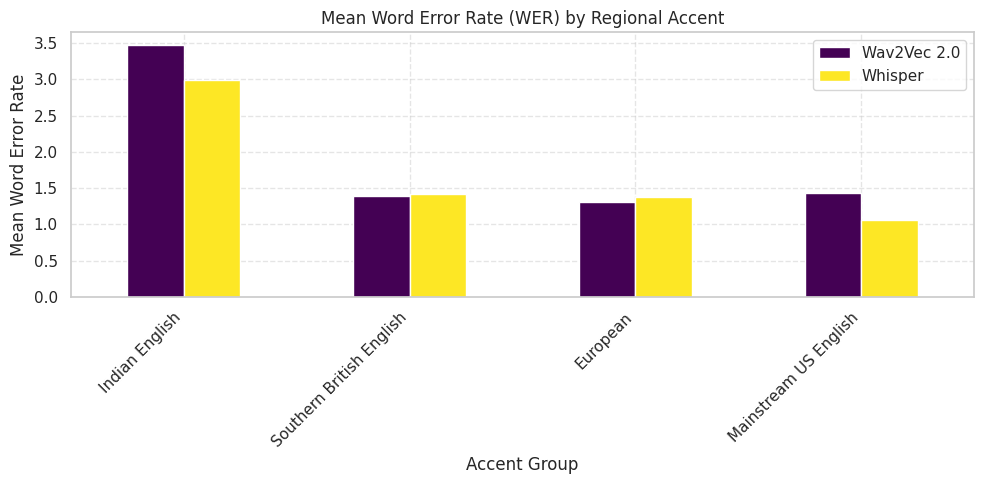

In [13]:
# Plotting the mean WER per accent for both models
accent_wer_summary.set_index('accent')[['w2v_mean_wer', 'whisper_mean_wer']].plot(
    kind='bar',
    figsize=(10, 5),
    colormap='viridis'
)

plt.title('Mean Word Error Rate (WER) by Regional Accent')
plt.xlabel('Accent Group')
plt.ylabel('Mean Word Error Rate')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(['Wav2Vec 2.0', 'Whisper'])
plt.tight_layout()
plt.show()

"Based on our evaluation of 500 samples from the EdAcc dataset, both Whisper and wav2vec 2.0 exhibited elevated error rates for Indian English, with wav2vec 2.0 consistently displaying a higher overall error rate than Whisper. Interestingly, the models diverged on mainstream US English: Whisper achieved lower error rates on US English than on European or Southern British accents, whereas wav2vec 2.0 unexpectedly struggled more with US English than with European or Southern British accents. Both models performed similarly on European and Southern British English. This behavioral shift strongly suggests underlying training data biases—namely, that Whisper's training corpus is heavily weighted toward North American English, while wav2vec 2.0's representation space shows distinct acoustic alignments elsewhere."

In [18]:
# Print all column names in your df_results dataframe to check their exact spelling
print(df_results.columns.tolist())

['id', 'accent', 'reference', 'w2v_pred', 'w2v_wer', 'w2v_conf', 'whisper_pred', 'whisper_wer', 'whisper_conf']


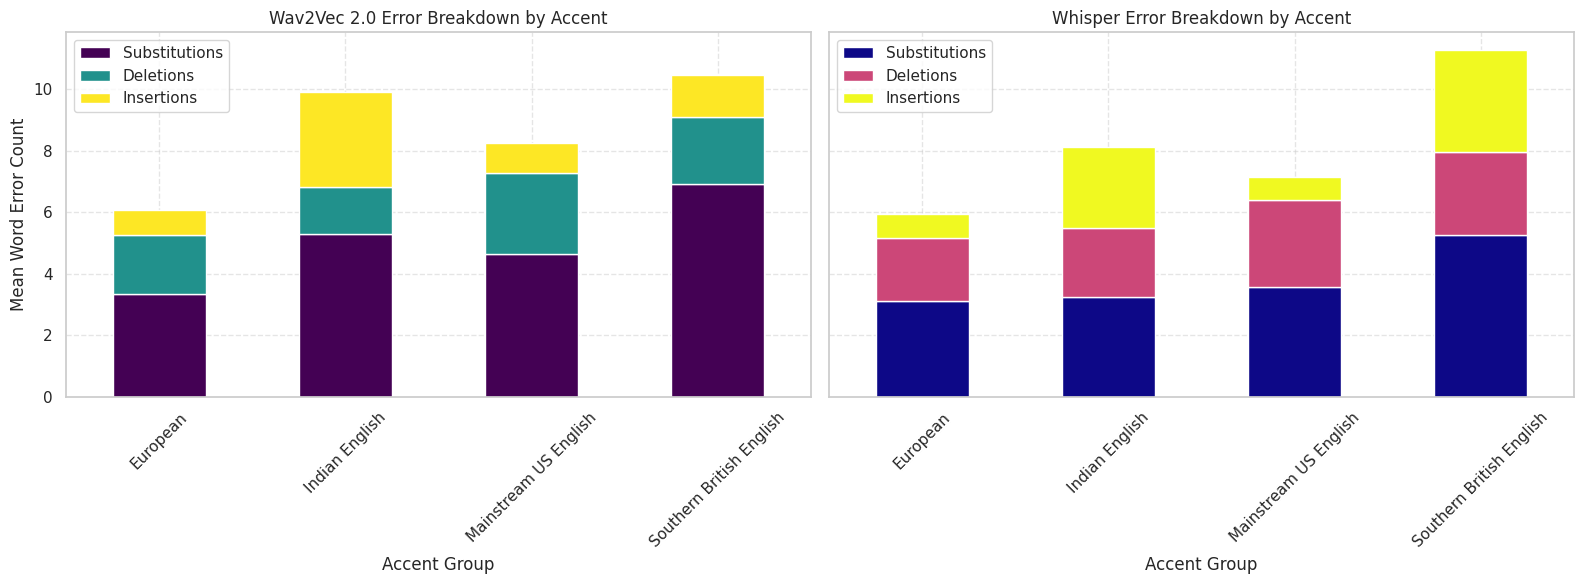

In [22]:
import jiwer
import matplotlib.pyplot as plt

# 1. Calculate substitutions, deletions, and insertions for BOTH models from existing text
w2v_subs, w2v_dels, w2v_ins = [], [], []
whisp_subs, whisp_dels, whisp_ins = [], [], []

for idx, row in df_results.iterrows():
    ref = str(row['reference']).lower()

    # Wav2Vec 2.0 error breakdown
    w2v_out = jiwer.process_words(ref, str(row['w2v_pred']).lower())
    w2v_subs.append(w2v_out.substitutions)
    w2v_dels.append(w2v_out.deletions)
    w2v_ins.append(w2v_out.insertions)

    # Whisper error breakdown
    whisp_out = jiwer.process_words(ref, str(row['whisper_pred']).lower())
    whisp_subs.append(whisp_out.substitutions)
    whisp_dels.append(whisp_out.deletions)
    whisp_ins.append(whisp_out.insertions)

# Add them to your dataframe
df_results['w2v_subs'] = w2v_subs
df_results['w2v_dels'] = w2v_dels
df_results['w2v_ins'] = w2v_ins

df_results['whisper_subs'] = whisp_subs
df_results['whisper_dels'] = whisp_dels
df_results['whisper_ins'] = whisp_ins

# 2. Group by accent and compute mean error breakdown for both models
df_w2v_err = df_results.groupby('accent')[['w2v_subs', 'w2v_dels', 'w2v_ins']].mean()
df_whisp_err = df_results.groupby('accent')[['whisper_subs', 'whisper_dels', 'whisper_ins']].mean()

# 3. Plot side-by-side stacked bar charts for comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Wav2Vec 2.0 Plot
df_w2v_err.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis')
axes[0].set_title('Wav2Vec 2.0 Error Breakdown by Accent')
axes[0].set_xlabel('Accent Group')
axes[0].set_ylabel('Mean Word Error Count')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(['Substitutions', 'Deletions', 'Insertions'])
axes[0].grid(True, linestyle='--', alpha=0.5)

# Whisper Plot
df_whisp_err.plot(kind='bar', stacked=True, ax=axes[1], colormap='plasma')
axes[1].set_title('Whisper Error Breakdown by Accent')
axes[1].set_xlabel('Accent Group')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(['Substitutions', 'Deletions', 'Insertions'])
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Phase I Error Breakdown Analysis: Wav2Vec 2.0 vs. Whisper
Based on our comparative error breakdown analysis (substitutions, deletions, and insertions) across the four accent groups, we observed distinct behavioral patterns for each speech recognition model:

1. Wav2Vec 2.0 Error Profile

Dominant Error Type: Substitutions (word confusion) account for the vast majority of errors across all accents, most notably in Southern British and Indian English.

Standard Hierarchy: For European, Mainstream US, and Southern British English, the error distribution consistently follows the order of substitutions > deletions > insertions.

The Indian English Anomaly: Indian English deviates from the standard hierarchy; while substitutions remain the primary error, they are followed by a high frequency of insertions (unexpected word additions), with deletions making up only a small fraction of the errors. Overall, Wav2Vec 2.0 generally displays lower insertion rates compared to deletion rates elsewhere.

2. Whisper Error Profile

Dominant Error Type: Substitutions are likewise the primary error type across all four accent groups for Whisper.

Shifting Secondary Errors: Whisper’s secondary error category varies by regional accent:

For Southern British and Indian English, insertions rank as the second most frequent error type, followed by deletions.

For European and Mainstream US English, deletions take precedence as the second most frequent error, followed by insertions.

Accent-Specific Behavior: Notably, Whisper exhibits a higher insertion rate than deletion rate specifically on the Southern British accent, contrasting with its behavior on other groups.

3. Cross-Model Comparison

Aside from the accent-specific deviations noted above (such as Wav2Vec 2.0’s insertion spike in Indian English and Whisper’s insertion behavior in Southern British English), both models share relatively consistent internal proportions of substitutions, deletions, and insertions across the remaining baseline accents.